# Predikcia dojazdu elektrických áut: ladenie hyperparametrov

V `modely.ipynb` sme porovnali modely s predvolenými nastaveniami. Najlepší bol Random Forest
(MAE ~21 km), Gradient Boosting skončil druhý (MAE ~31 km). Tu oba stromové modely vyladíme
cez `GridSearchCV` a zistíme, ktorý je naozaj lepší.

Testovacie dáta ani tu nepoužijeme. Všetko ladíme iba krížovou validáciou na trénovacích dátach.

*Spustenie celého notebooku trvá niekoľko minút, `GridSearchCV` trénuje stovky modelov.*

## 1. Príprava dát

Rovnaké kroky ako v `preprocessing.ipynb` a `modely.ipynb`, s rovnakým rozdelením na tréning a test.
Stromové modely nepotrebujú škálovanie, preto stačí `prep_stromy`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

data = pd.read_csv('data/ev_clean.csv')
y = data['range_km']
X = data.drop(columns='range_km')

num_col = X.select_dtypes(include='number').columns.tolist()
cat_col = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42)

prep_stromy = ColumnTransformer([
    ('num', 'passthrough', num_col),
    ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist',
                          sparse_output=False), cat_col),
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

print('Tréning:', X_train.shape, ' Test:', X_test.shape)

Tréning: (1268, 8)  Test: (317, 8)


## 2. Čo je ladenie hyperparametrov

**Parametre** sa model učí z dát sám (napríklad podľa ktorej hodnoty a pri akej hranici strom delí autá).
**Hyperparametre** nastavujeme my ešte pred učením (napríklad koľko stromov má les alebo aké hlboké
môžu byť). Model si ich z dát nevie zistiť, preto ich musíme vyskúšať.

**`GridSearchCV`** skúša hyperparametre systematicky:

1. Pre každý hyperparameter zadáme zoznam hodnôt. Tento zoznam sa volá **mriežka** (*grid*).
2. `GridSearchCV` vyskúša **každú kombináciu**. Pri 3 hyperparametroch s 3 hodnotami je to
   3 × 3 × 3 = 27 kombinácií.
3. Každú kombináciu ohodnotí krížovou validáciou (5 foldov), teda pri 27 kombináciách natrénuje 135 modelov.
4. Vyberie kombináciu s najlepším priemerným skóre a model s ňou natrénuje znova na všetkých trénovacích
   dátach (`refit=True`). Ten je potom v `best_estimator_`.

**Názvy hyperparametrov v `Pipeline`:** model je v kroku pomenovanom `'model'`, preto pred názov
hyperparametra píšeme `model__` (dve podčiarkovníky). `model__max_depth` znamená
„hyperparameter `max_depth` kroku `model`“.

**Hlavné nastavenia:**

- **`scoring='neg_mean_absolute_error'`:** vyberáme podľa MAE (so záporným znamienkom, lebo sklearn
  vždy hľadá maximum).
- **`n_jobs=-1`:** modely trénuje paralelne na všetkých jadrách procesora.
- **`return_train_score=True`:** uloží aj chybu na tréningu, aby sme videli overfitting.

In [2]:
def najlepsie(gs, n=5):
    # tabuľka n najlepších kombinácií z GridSearchCV, chyby v km
    r = pd.DataFrame(gs.cv_results_).sort_values('rank_test_score')
    parametre = [c for c in r.columns if c.startswith('param_')]
    tabulka = r[parametre].rename(columns=lambda c: c.replace('param_model__', ''))
    tabulka['MAE'] = -r['mean_test_score']
    tabulka['MAE std'] = r['std_test_score']
    tabulka['MAE tréning'] = -r['mean_train_score']
    return tabulka.head(n).round(2).reset_index(drop=True)

## 3. Random Forest

Ladíme štyri hyperparametre:

- **`n_estimators`:** počet stromov. Viac stromov znamená stabilnejší priemer, ale pomalší výpočet.
- **`max_depth`:** maximálna hĺbka stromu. `None` znamená bez obmedzenia, strom delí, kým to ide.
- **`min_samples_leaf`:** najmenší počet áut v liste stromu. Väčšie číslo robí strom jednoduchším.
- **`max_features`:** koľko príznakov (podiel) strom pri každom delení zvažuje. `1.0` znamená všetky,
  `0.5` polovicu náhodne vybraných. Menej príznakov robí stromy rozdielnejšími.

Mriežka má 2 × 3 × 3 × 2 = 36 kombinácií, teda 180 trénovaní.

In [3]:
rf = Pipeline([
    ('prep', prep_stromy),
    ('model', RandomForestRegressor(random_state=42)),
])

mriezka_rf = {
    'model__n_estimators': [200, 500],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [1.0, 0.5],
}

gs_rf = GridSearchCV(rf, mriezka_rf, cv=cv, scoring='neg_mean_absolute_error',
                     n_jobs=-1, return_train_score=True)
gs_rf.fit(X_train, y_train)

print('Najlepšie hyperparametre:', gs_rf.best_params_)
print(f'Najlepšie MAE: {-gs_rf.best_score_:.2f} km')
najlepsie(gs_rf)

Najlepšie hyperparametre: {'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_leaf': 1, 'model__n_estimators': 500}
Najlepšie MAE: 20.75 km


,max_depth,max_features,min_samples_leaf,n_estimators,MAE,MAE std,MAE tréning
0,None,1.0,1,500,20.75,1.12,7.74
1,20,1.0,1,500,20.89,1.07,8.06
2,None,1.0,1,200,20.90,1.15,7.74
3,None,0.5,1,500,20.99,1.07,7.84
4,20,1.0,1,200,21.02,1.04,8.06


Ladenie Random Forestu skoro nepomohlo. Najlepšia kombinácia je takmer zhodná s predvolenými
nastaveniami (stromy bez obmedzenia hĺbky, všetky príznaky, 1 auto v liste), iba má viac stromov.
Predvolené nastavenia Random Forestu sú vo všeobecnosti dobré, preto sa často používa bez ladenia.

## 4. Gradient Boosting

Pri Gradient Boostingu ladíme:

- **`n_estimators`:** počet stromov, teda koľkokrát model opravuje svoje chyby.
- **`learning_rate`:** ako veľmi každý nový strom opraví predchádzajúce chyby. Menšia hodnota znamená
  opatrnejšie učenie, ktoré potrebuje viac stromov.
- **`max_depth`:** hĺbka každého stromu. Predvolené 3 je dosť plytké.
- **`subsample`:** podiel áut, na ktorých sa učí každý strom. `0.8` znamená náhodných 80 %, čo pridá
  trochu náhody a môže znížiť overfitting.

### 4.1 Hrubá mriežka

Najprv skúsime široký rozsah hodnôt: 3 × 2 × 3 × 2 = 36 kombinácií.

In [4]:
gb = Pipeline([
    ('prep', prep_stromy),
    ('model', GradientBoostingRegressor(random_state=42)),
])

mriezka_gb = {
    'model__n_estimators': [200, 500, 1000],
    'model__learning_rate': [0.03, 0.1],
    'model__max_depth': [3, 5, 7],
    'model__subsample': [0.8, 1.0],
}

gs_gb = GridSearchCV(gb, mriezka_gb, cv=cv, scoring='neg_mean_absolute_error',
                     n_jobs=-1, return_train_score=True)
gs_gb.fit(X_train, y_train)

print('Najlepšie hyperparametre:', gs_gb.best_params_)
print(f'Najlepšie MAE: {-gs_gb.best_score_:.2f} km')
najlepsie(gs_gb)

Najlepšie hyperparametre: {'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 1000, 'model__subsample': 0.8}
Najlepšie MAE: 16.16 km


,learning_rate,max_depth,n_estimators,subsample,MAE,MAE std,MAE tréning
0,0.10,7,1000,0.8,16.16,1.19,0.43
1,0.10,7,500,0.8,16.25,1.25,0.75
2,0.03,7,1000,0.8,16.35,1.20,1.34
3,0.10,7,1000,1.0,16.66,1.08,0.28
4,0.10,7,500,1.0,16.72,1.09,0.48


Gradient Boosting sa zlepšil výrazne, z ~31 km na ~16 km. Pozor však na jednu vec: najlepšia hodnota
`max_depth=7` je **najväčšia hodnota v mriežke**. Graf ukazuje, ako sa chyba mení s hĺbkou a počtom
stromov (pri `learning_rate=0.1` a `subsample=0.8`).

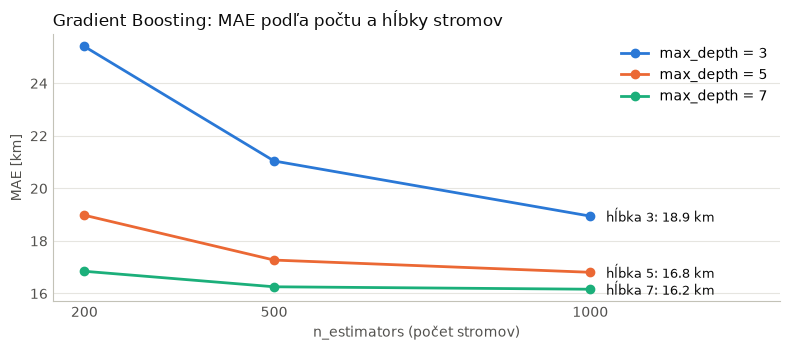

In [5]:
MODRA, ORANZOVA, TYRKYSOVA, SIVA = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae'
TEXT, TEXT_2, MRIEZKA = '#0b0b0b', '#52514e', '#e6e5e0'

def uprav_osi(ax):
    ax.tick_params(colors=TEXT_2, length=0)
    ax.set_axisbelow(True)
    for strana in ['top', 'right']:
        ax.spines[strana].set_visible(False)
    for strana in ['bottom', 'left']:
        ax.spines[strana].set_color('#c3c2b7')

r = pd.DataFrame(gs_gb.cv_results_)
vyber = r[(r['param_model__learning_rate'] == 0.1) & (r['param_model__subsample'] == 0.8)]

fig, ax = plt.subplots(figsize=(8, 3.6))
for farba, (hlbka, skupina) in zip([MODRA, ORANZOVA, TYRKYSOVA],
                                   vyber.groupby('param_model__max_depth')):
    skupina = skupina.sort_values('param_model__n_estimators')
    stromy, mae = skupina['param_model__n_estimators'], -skupina['mean_test_score']
    ax.plot(stromy, mae, color=farba, linewidth=2, marker='o', markersize=6, label=f'max_depth = {hlbka}')
    ax.text(stromy.iloc[-1] + 25, mae.iloc[-1], f'hĺbka {hlbka}: {mae.iloc[-1]:.1f} km',
            va='center', color=TEXT, fontsize=9)

ax.set_title('Gradient Boosting: MAE podľa počtu a hĺbky stromov', loc='left', color=TEXT)
ax.set_xlabel('n_estimators (počet stromov)', color=TEXT_2)
ax.set_ylabel('MAE [km]', color=TEXT_2)
ax.set_xticks([200, 500, 1000])
ax.set_xlim(150, 1300)
ax.grid(axis='y', color=MRIEZKA, linewidth=0.8)
ax.legend(frameon=False, loc='upper right')
uprav_osi(ax)
plt.tight_layout()
plt.show()

Hlbšie stromy aj viac stromov chybu znižujú a čiara pre hĺbku 7 je najnižšia. Nevieme však, či by
hĺbka 9 alebo 12 nebola ešte lepšia, lebo sme ju neskúšali.

**Pravidlo:** keď najlepšia hodnota leží na okraji mriežky, mriežku treba za týmto okrajom rozšíriť.
Optimum môže byť mimo nej.

### 4.2 Jemná mriežka

Okolo najlepšieho výsledku skúsime hlbšie stromy a pridáme `min_samples_leaf`, ktorý hlboké stromy
trochu zjednoduší. Počet stromov necháme na 1000. Z hrubej mriežky vidno, že ďalšie stromy pridávajú
už len málo a výpočet výrazne spomaľujú. `subsample=0.8` bol v hrubej mriežke lepší pri všetkých
najlepších kombináciách, preto ho tiež zafixujeme. Mriežka má 2 × 3 × 3 = 18 kombinácií.

In [6]:
gb_jemny = Pipeline([
    ('prep', prep_stromy),
    ('model', GradientBoostingRegressor(n_estimators=1000, subsample=0.8, random_state=42)),
])

mriezka_gb_jemna = {
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [7, 9, 12],
    'model__min_samples_leaf': [1, 3, 5],
}

gs_gb_jemny = GridSearchCV(gb_jemny, mriezka_gb_jemna, cv=cv, scoring='neg_mean_absolute_error',
                           n_jobs=-1, return_train_score=True)
gs_gb_jemny.fit(X_train, y_train)

print('Najlepšie hyperparametre:', gs_gb_jemny.best_params_)
print(f'Najlepšie MAE: {-gs_gb_jemny.best_score_:.2f} km')
najlepsie(gs_gb_jemny, n=8)

Najlepšie hyperparametre: {'model__learning_rate': 0.05, 'model__max_depth': 7, 'model__min_samples_leaf': 1}
Najlepšie MAE: 16.15 km


,learning_rate,max_depth,min_samples_leaf,MAE,MAE std,MAE tréning
0,0.05,7,1,16.15,1.27,0.72
1,0.10,7,1,16.16,1.19,0.43
2,0.05,9,1,16.50,0.81,0.36
3,0.05,7,3,16.57,1.38,1.56
4,0.05,9,3,16.59,1.28,0.81
5,0.10,9,1,16.63,1.33,0.29
6,0.10,9,3,16.73,1.35,0.45
7,0.10,7,3,16.76,1.56,0.80


In [7]:
# priemerné MAE podľa hĺbky stromov (cez všetky ostatné kombinácie)
r = pd.DataFrame(gs_gb_jemny.cv_results_)
(-r.groupby('param_model__max_depth')['mean_test_score'].mean()).round(2).rename('priemerné MAE')

param_model__max_depth
7     16.75
9     16.77
12    17.29
Name: priemerné MAE, dtype: float64

Hlbšie stromy (9 a 12) sú horšie, takže hĺbka 7 je skutočné optimum, už nie okraj mriežky.
Jemná mriežka priniesla oproti hrubej len malé zlepšenie. Hlavný skok spravila hrubá mriežka,
keď sme pustili hlbšie stromy a viac stromov.

## 5. Overfitting a kontrola dvojčiat

Tréningová chyba vyladeného Gradient Boostingu je pod 1 km, validačná okolo 16 km. Model si trénovacie
autá pamätá takmer naspamäť. To samo o sebe nevadí, pretože o výbere rozhoduje validačná chyba a tá je
najlepšia zo všetkých modelov.

Model, ktorý si dáta pamätá, však môže ťažiť z áut s rovnakými príznakmi („dvojčiat“) z `modely.ipynb`.
Ak je jedno v tréningu a druhé vo validácii, model si ho iba zapamätá. Preto obe vyladené modely
overíme aj cez `GroupKFold`, ktorý dvojčatá nikdy nerozdelí.

In [8]:
from sklearn.model_selection import GroupKFold

skupiny = X_train.astype(str).agg('|'.join, axis=1)
cv_skupiny = GroupKFold(n_splits=5, shuffle=True, random_state=42)

def mae_cv(model, cv, groups=None):
    vysledky = cross_validate(model, X_train, y_train, cv=cv, groups=groups,
                              scoring='neg_mean_absolute_error', n_jobs=-1)
    return -vysledky['test_score'].mean()

kandidati = {
    'Random Forest': (rf, gs_rf.best_estimator_),
    'Gradient Boosting': (gb, gs_gb_jemny.best_estimator_),
}

riadky = []
for nazov, (predvoleny, vyladeny) in kandidati.items():
    riadky.append({
        'model': nazov,
        'predvolený (KFold)': mae_cv(predvoleny, cv),
        'vyladený (KFold)': mae_cv(vyladeny, cv),
        'vyladený (GroupKFold)': mae_cv(vyladeny, cv_skupiny, skupiny),
    })

vysledok = pd.DataFrame(riadky).set_index('model')
vysledok.round(1)

,predvolený (KFold),vyladený (KFold),vyladený (GroupKFold)
model,,,
Random Forest,20.9,20.7,20.8
Gradient Boosting,31.2,16.2,17.0


Pri `GroupKFold` je chyba vyladeného Gradient Boostingu asi o 1 km väčšia. Dvojčatá mu teda trochu
pomáhajú, no stále je jasne lepší ako Random Forest. Ten má s `GroupKFold` rovnakú chybu ako s `KFold`.

*Prečo `rf` a `gb` vyjdú ako predvolené modely: `GridSearchCV` pôvodné pipeline nemení, na každú
kombináciu si vytvorí kópiu. Vyladený model je iba v `best_estimator_`.*

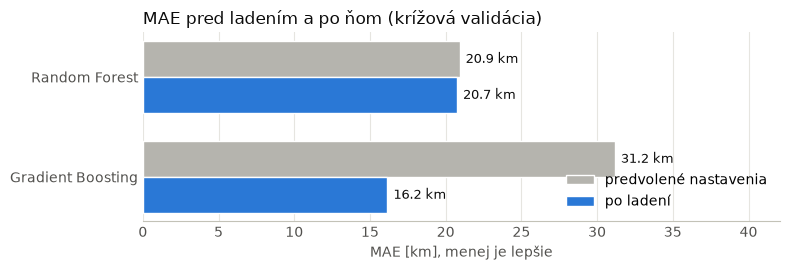

In [9]:
poradie = vysledok.iloc[::-1]
pozicie = range(len(poradie))
vyska = 0.36

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh([p + vyska / 2 for p in pozicie], poradie['predvolený (KFold)'], height=vyska,
        color=SIVA, label='predvolené nastavenia', edgecolor='white', linewidth=1)
ax.barh([p - vyska / 2 for p in pozicie], poradie['vyladený (KFold)'], height=vyska,
        color=MODRA, label='po ladení', edgecolor='white', linewidth=1)
for p, (pred, po) in zip(pozicie, zip(poradie['predvolený (KFold)'], poradie['vyladený (KFold)'])):
    ax.text(pred + 0.4, p + vyska / 2, f'{pred:.1f} km', va='center', color=TEXT, fontsize=9)
    ax.text(po + 0.4, p - vyska / 2, f'{po:.1f} km', va='center', color=TEXT, fontsize=9)

ax.set_yticks(list(pozicie), poradie.index)
ax.set_title('MAE pred ladením a po ňom (krížová validácia)', loc='left', color=TEXT)
ax.set_xlabel('MAE [km], menej je lepšie', color=TEXT_2)
ax.set_xlim(0, poradie['predvolený (KFold)'].max() * 1.35)
ax.grid(axis='x', color=MRIEZKA, linewidth=0.8)
ax.legend(frameon=False, loc='lower right')
uprav_osi(ax)
ax.spines['left'].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Zhrnutie

- **Random Forest:** ladenie skoro nepomohlo, predvolené nastavenia boli takmer optimálne.
- **Gradient Boosting:** po ladení je najlepší model. Rozhodli hlbšie stromy (`max_depth=7`
  namiesto 3) a viac stromov (1000 namiesto 100).
- Hrubá mriežka našla optimum na okraji, preto sme ju rozšírili. Hlbšie stromy už boli horšie.
- Kontrola cez `GroupKFold` ukázala, že dvojčatá výsledok Gradient Boostingu trochu zlepšujú (~1 km),
  ale na poradí modelov to nič nemení.

**Pozor na optimizmus:** najlepšie skóre z `GridSearchCV` je najlepšie z desiatok pokusov. Časť
zlepšenia môže byť náhoda, kombinácia mohla „mať šťastie“ práve na týchto foldoch. Preto skutočnú
chybu zmeriame až na testovacích dátach, ktoré pri ladení nikto nevidel.

## 7. Ďalší krok

1. **Finálne vyhodnotenie** vyladeného Gradient Boostingu na testovacích dátach, iba raz.
2. **Rozbor chýb:** graf predpovedaný vs. skutočný dojazd, autá s najväčšou chybou a dôležitosť príznakov.